<a href="https://colab.research.google.com/github/solaxttp/ml/blob/main/lab3ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Автоматичне встановлення відсутніх залежностей (працює у Colab/Jupyter)
import importlib.util, os, re, subprocess, sys, warnings, zipfile
from pathlib import Path

REQUIRED_PACKAGES = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'sklearn': 'scikit-learn',
    'gensim': 'gensim',
    'spacy': 'spacy',
    'requests': 'requests',
}
missing = [
    pip_name
    for module, pip_name in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(module) is None
]
if missing:
  print('Встановлення відсутніх пакетів:', ', '.join(missing))
  subprocess.check_call(
      [sys.executable, '-m', 'pip', 'install', '-q', *missing]
  )
  print(
      'Пакети встановлено. Якщо імпорт не оновився автоматично, перезапустіть'
      ' runtime і виконайте всі комірки.'
  )

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
print('Python:', sys.version.split()[0])

Встановлення відсутніх пакетів: gensim
Пакети встановлено. Якщо імпорт не оновився автоматично, перезапустіть runtime і виконайте всі комірки.
Python: 3.13.18


In [ ]:
import requests

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
CSV_PATH = DATA_DIR / 'ai_vs_human_text_2026.csv'
DATASET_URL = 'https://www.kaggle.com/api/v1/datasets/download/alitaqishah/ai-vs-human-text-classification-dataset-2026'

if not CSV_PATH.exists():
  zip_path = DATA_DIR / 'dataset.zip'
  response = requests.get(DATASET_URL, timeout=120)
  response.raise_for_status()
  zip_path.write_bytes(response.content)
  with zipfile.ZipFile(zip_path) as zf:
    zf.extractall(DATA_DIR)
  zip_path.unlink(missing_ok=True)

df_raw = pd.read_csv(CSV_PATH)
print('Розмір сирого датасету:', df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.to_frame('dtype'))

Розмір сирого датасету: (2000, 9)


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


,dtype
text_id,object
label,object
source_model,object
domain,object
text_content,object
topic_hint,object
word_count,int64
avg_sentence_length,float64
generation_method,object


,Показник,Значення
0,Рядків,2000
1,Пропусків у тексті,0
2,Пропусків у мітці,0
3,Повних дублікатів,0
4,Дублікатів тексту,1034


Розмір після очищення: (966, 11)

Баланс класів:


,count,percent
label,,
human,579,59.94
ai,387,40.06


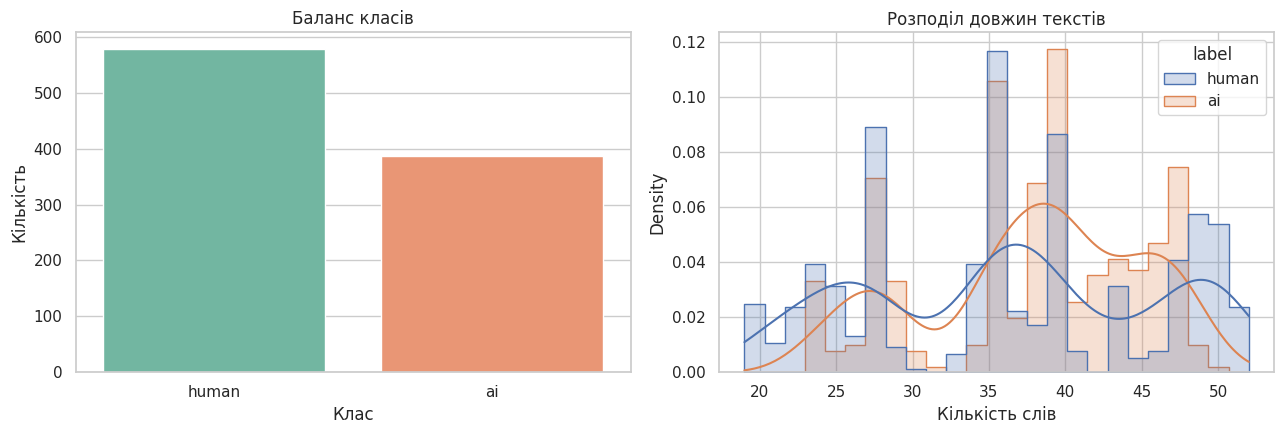

,count,mean,median,std,min,max
label,,,,,,
ai,387,37.93,39.0,7.03,23,50
human,579,36.35,36.0,9.40,19,52


In [ ]:
TEXT_COL, LABEL_COL = 'text_content', 'label'
required = {TEXT_COL, LABEL_COL}
assert required.issubset(
    df_raw.columns
), f'Відсутні колонки: {required - set(df_raw.columns)}'

eda = pd.DataFrame({
    'Показник': [
        'Рядків',
        'Пропусків у тексті',
        'Пропусків у мітці',
        'Повних дублікатів',
        'Дублікатів тексту',
    ],
    'Значення': [
        len(df_raw),
        df_raw[TEXT_COL].isna().sum(),
        df_raw[LABEL_COL].isna().sum(),
        df_raw.duplicated().sum(),
        df_raw.duplicated(TEXT_COL).sum(),
    ],
})
display(eda)

# Очищення артефактів
df = df_raw.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df = (
    df[df[TEXT_COL].str.len() > 0]
    .drop_duplicates(subset=[TEXT_COL])
    .reset_index(drop=True)
)
df['word_count_calc'] = df[TEXT_COL].str.split().str.len()
df = df[df['word_count_calc'] >= 3].reset_index(drop=True)

df['target'] = (
    df[LABEL_COL].astype(str).str.lower().map({'human': 0, 'ai': 1})
)
assert df['target'].notna().all(), 'Знайдені невідомі мітки класів'

print('Розмір після очищення:', df.shape)
print('\nБаланс класів:')
display(
    pd.concat(
        [
            df[LABEL_COL].value_counts().rename('count'),
            df[LABEL_COL]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
            .rename('percent'),
        ],
        axis=1,
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(
    data=df, x=LABEL_COL, hue=LABEL_COL, palette='Set2', legend=False, ax=axes[0]
)
axes[0].set_title('Баланс класів')
axes[0].set_xlabel('Клас')
axes[0].set_ylabel('Кількість')
sns.histplot(
    data=df,
    x='word_count_calc',
    hue=LABEL_COL,
    bins=25,
    kde=True,
    element='step',
    stat='density',
    common_norm=False,
    ax=axes[1],
)
axes[1].set_title('Розподіл довжин текстів')
axes[1].set_xlabel('Кількість слів')
plt.tight_layout()
plt.show()

display(
    df.groupby(LABEL_COL)['word_count_calc']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

In [ ]:
import spacy

try:
  nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
except OSError:
  print('Модель en_core_web_sm не знайдена — завантаження...')
  subprocess.check_call(
      [sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm']
  )
  nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])


def preprocess_pipe(texts, batch_size=128):
  result = []
  for doc in nlp.pipe(texts, batch_size=batch_size):
    tokens = [
        t.lemma_.lower()
        for t in doc
        if t.is_alpha and not t.is_stop and t.lemma_.strip()
    ]
    result.append(tokens)
  return result


df['tokens'] = preprocess_pipe(df[TEXT_COL].tolist())
empty_after = df['tokens'].str.len().eq(0).sum()
print('Порожніх документів після обробки:', empty_after)
df = df[df['tokens'].str.len() > 0].reset_index(drop=True)
display(df[[TEXT_COL, 'tokens', LABEL_COL]].head(5))

Порожніх документів після обробки: 0


,text_content,tokens,label
0,can we talk about gene editing ethics for a se...,"[talk, gene, edit, ethic, sec, feel, like, peo...",human
1,update on election integrity concerns: it's co...,"[update, election, integrity, concern, complic...",human
2,Analysts are closely watching developments rel...,"[analyst, closely, watch, development, relate,...",ai
3,This paper examines genomic research breakthro...,"[paper, examine, genomic, research, breakthrou...",human
4,Existing literature on student debt crisis has...,"[exist, literature, student, debt, crisis, pre...",ai


In [ ]:
import re
from gensim.models import FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold


def make_template_group(row):
  # Прибираємо змінні частини шаблону, не використовуючи мітку класу.
  text = str(row[TEXT_COL]).lower()
  topic = str(row.get('topic_hint', '')).lower().strip()
  if topic and topic != 'nan':
    text = text.replace(topic, ' <topic> ')
  text = re.sub(r'\b\d+(?:[.,]\d+)?\b', ' <num> ', text)
  text = re.sub(
      r'\b(?:monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b',
      ' <day> ',
      text,
  )
  text = re.sub(r'[^a-z<>]+', ' ', text)
  return ' '.join(text.split())


df['template_group'] = df.apply(make_template_group, axis=1)
indices = np.arange(len(df))
y = df['target'].to_numpy(dtype=int)
groups = df['template_group'].to_numpy()

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(indices, y, groups=groups))

train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])
assert train_groups.isdisjoint(
    test_groups
), 'Виявлено перетин шаблонів між train і test'

print('Кількість документів:', len(df))
print('Кількість шаблонних груп:', df['template_group'].nunique())
print('Train/Test:', len(train_idx), '/', len(test_idx))
print('Групи Train/Test:', len(train_groups), '/', len(test_groups))
print('Перетин груп:', len(train_groups & test_groups))
print(
    'Баланс train:',
    pd.Series(y[train_idx]).value_counts().sort_index().to_dict(),
)
print(
    'Баланс test:', pd.Series(y[test_idx]).value_counts().sort_index().to_dict()
)

train_tokens = df.iloc[train_idx]['tokens'].tolist()
test_tokens = df.iloc[test_idx]['tokens'].tolist()
y_train, y_test = y[train_idx], y[test_idx]

ft_model = FastText(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=SEED,
    epochs=20,
)
print('FastText vocabulary:', len(ft_model.wv.key_to_index))

# sklearn отримує вже токенізовані документи
tfidf = TfidfVectorizer(analyzer=lambda x: x, lowercase=False)
X_tfidf_train = tfidf.fit_transform(train_tokens)
X_tfidf_test = tfidf.transform(test_tokens)
features = tfidf.get_feature_names_out()


def mean_pooling(tokens, model):
  vectors = [model.wv[t] for t in tokens]
  return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)


def tfidf_weighted_matrix(token_lists, sparse_matrix, model, feature_names):
  result = np.zeros((len(token_lists), model.vector_size), dtype=np.float32)
  for row_i in range(sparse_matrix.shape[0]):
    row = sparse_matrix.getrow(row_i)
    vectors, weights = [], []
    for col_i, weight in zip(row.indices, row.data):
      token = feature_names[col_i]
      vectors.append(model.wv[token])
      weights.append(weight)
    if vectors:
      result[row_i] = np.average(vectors, axis=0, weights=np.asarray(weights))
  return result


X_mean_train = np.vstack([mean_pooling(t, ft_model) for t in train_tokens])
X_mean_test = np.vstack([mean_pooling(t, ft_model) for t in test_tokens])
X_weighted_train = tfidf_weighted_matrix(
    train_tokens, X_tfidf_train, ft_model, features
)
X_weighted_test = tfidf_weighted_matrix(
    test_tokens, X_tfidf_test, ft_model, features
)

representations = {
    'Mean Pooling': (X_mean_train, X_mean_test),
    'TF-IDF Weighted Mean': (X_weighted_train, X_weighted_test),
}
for name, (tr, te) in representations.items():
  print(
      f'{name}: train={tr.shape}, test={te.shape},'
      f' NaN={np.isnan(tr).sum()+np.isnan(te).sum()}'
  )

Кількість документів: 966
Кількість шаблонних груп: 34
Train/Test: 784 / 182
Групи Train/Test: 28 / 6
Перетин груп: 0
Баланс train: {0: 484, 1: 300}
Баланс test: {0: 95, 1: 87}
FastText vocabulary: 447
Mean Pooling: train=(784, 100), test=(182, 100), NaN=0
TF-IDF Weighted Mean: train=(784, 100), test=(182, 100), NaN=0


,Агрегація,Класифікатор,F1 macro,Accuracy,Balanced Accuracy,ROC-AUC
0,TF-IDF Weighted Mean,KNN,0.4131,0.4505,0.4626,0.4512
1,TF-IDF Weighted Mean,SVM (RBF),0.4106,0.4835,0.4999,0.3481
2,TF-IDF Weighted Mean,Logistic Regression,0.3718,0.3846,0.3917,0.3216
3,Mean Pooling,SVM (RBF),0.3234,0.4780,0.5000,0.1719
4,Mean Pooling,KNN,0.3132,0.4560,0.4770,0.4716
5,Mean Pooling,Logistic Regression,0.2661,0.3626,0.3793,0.1827


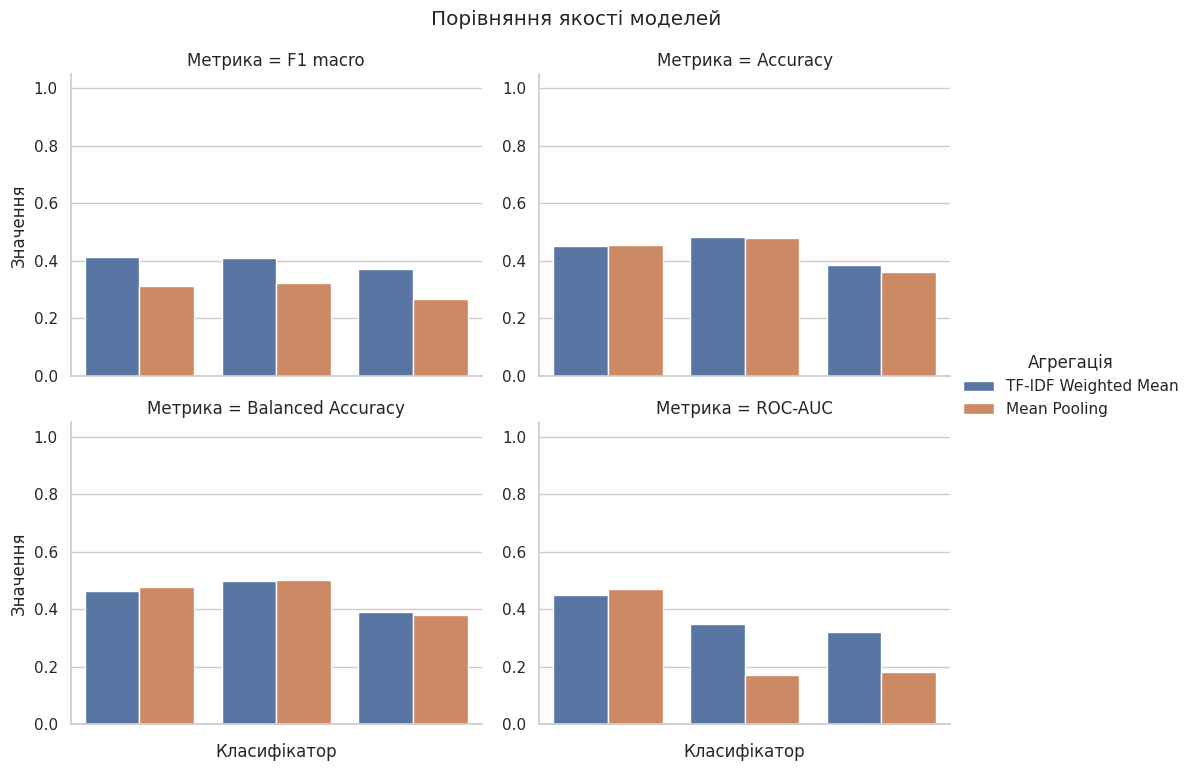

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

models = {
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=SEED),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=5),
}

rows, fitted, predictions = [], {}, {}
for repr_name, (X_train, X_test) in representations.items():
  for model_name, estimator in models.items():
    pipe = make_pipeline(StandardScaler(), estimator)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1]
    fitted[(repr_name, model_name)] = pipe
    predictions[(repr_name, model_name)] = pred
    rows.append({
        'Агрегація': repr_name,
        'Класифікатор': model_name,
        'F1 macro': f1_score(y_test, pred, average='macro'),
        'Accuracy': accuracy_score(y_test, pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, score),
    })

results = (
    pd.DataFrame(rows)
    .sort_values(['F1 macro', 'ROC-AUC'], ascending=False)
    .reset_index(drop=True)
)
display(
    results.style.format({
        c: '{:.4f}'
        for c in ['F1 macro', 'Accuracy', 'Balanced Accuracy', 'ROC-AUC']
    }).background_gradient(
        subset=['F1 macro', 'Accuracy', 'Balanced Accuracy', 'ROC-AUC'],
        cmap='YlGn',
    )
)
results.to_csv('classification_results.csv', index=False)

metric_long = results.melt(
    id_vars=['Агрегація', 'Класифікатор'],
    var_name='Метрика',
    value_name='Значення',
)
g = sns.catplot(
    data=metric_long,
    x='Класифікатор',
    y='Значення',
    hue='Агрегація',
    col='Метрика',
    kind='bar',
    col_wrap=2,
    height=4,
    aspect=1.25,
    sharey=False,
)
g.set_xticklabels(rotation=20)
g.set(ylim=(0, 1.05))
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle('Порівняння якості моделей')
plt.show()

In [ ]:
from sklearn.base import clone

cv_rows = []
group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (fold_train_idx, fold_test_idx) in enumerate(
    group_cv.split(indices, y, groups), start=1
):
  assert set(groups[fold_train_idx]).isdisjoint(set(groups[fold_test_idx]))
  fold_train_tokens = df.iloc[fold_train_idx]['tokens'].tolist()
  fold_test_tokens = df.iloc[fold_test_idx]['tokens'].tolist()
  fold_y_train, fold_y_test = y[fold_train_idx], y[fold_test_idx]

  fold_ft = FastText(
      sentences=fold_train_tokens,
      vector_size=100,
      window=5,
      min_count=2,
      sg=1,
      workers=1,
      seed=SEED,
      epochs=20,
  )
  fold_tfidf = TfidfVectorizer(analyzer=lambda x: x, lowercase=False)
  fold_sparse_train = fold_tfidf.fit_transform(fold_train_tokens)
  fold_sparse_test = fold_tfidf.transform(fold_test_tokens)
  fold_features = fold_tfidf.get_feature_names_out()

  fold_mean_train = np.vstack(
      [mean_pooling(t, fold_ft) for t in fold_train_tokens]
  )
  fold_mean_test = np.vstack(
      [mean_pooling(t, fold_ft) for t in fold_test_tokens]
  )
  fold_weighted_train = tfidf_weighted_matrix(
      fold_train_tokens, fold_sparse_train, fold_ft, fold_features
  )
  fold_weighted_test = tfidf_weighted_matrix(
      fold_test_tokens, fold_sparse_test, fold_ft, fold_features
  )

  fold_representations = {
      'Mean Pooling': (fold_mean_train, fold_mean_test),
      'TF-IDF Weighted Mean': (fold_weighted_train, fold_weighted_test),
  }
  for repr_name, (fold_X_train, fold_X_test) in fold_representations.items():
    for model_name, estimator in models.items():
      fold_pipe = make_pipeline(StandardScaler(), clone(estimator))
      fold_pipe.fit(fold_X_train, fold_y_train)
      fold_pred = fold_pipe.predict(fold_X_test)
      fold_score = fold_pipe.predict_proba(fold_X_test)[:, 1]
      cv_rows.append({
          'Fold': fold,
          'Агрегація': repr_name,
          'Класифікатор': model_name,
          'F1 macro': f1_score(fold_y_test, fold_pred, average='macro'),
          'Accuracy': accuracy_score(fold_y_test, fold_pred),
          'Balanced Accuracy': balanced_accuracy_score(fold_y_test, fold_pred),
          'ROC-AUC': roc_auc_score(fold_y_test, fold_score),
      })

cv_results = pd.DataFrame(cv_rows)
cv_summary = (
    cv_results.groupby(['Агрегація', 'Класифікатор'])
    .agg(
        F1_mean=('F1 macro', 'mean'),
        F1_std=('F1 macro', 'std'),
        Accuracy_mean=('Accuracy', 'mean'),
        Balanced_Accuracy_mean=('Balanced Accuracy', 'mean'),
        ROC_AUC_mean=('ROC-AUC', 'mean'),
    )
    .reset_index()
    .sort_values('F1_mean', ascending=False)
)
display(
    cv_summary.style.format({c: '{:.4f}' for c in cv_summary.columns[2:]})
)
cv_results.to_csv('grouped_cv_fold_results.csv', index=False)
cv_summary.to_csv('grouped_cv_summary.csv', index=False)

,Агрегація,Класифікатор,F1_mean,F1_std,Accuracy_mean,Balanced_Accuracy_mean,ROC_AUC_mean
5,TF-IDF Weighted Mean,SVM (RBF),0.4763,0.1635,0.5116,0.5638,0.5359
4,TF-IDF Weighted Mean,Logistic Regression,0.4261,0.1540,0.4578,0.5054,0.3852
3,TF-IDF Weighted Mean,KNN,0.4239,0.0557,0.4507,0.4955,0.5315
0,Mean Pooling,KNN,0.4101,0.1468,0.4528,0.5262,0.5336
2,Mean Pooling,SVM (RBF),0.3947,0.1590,0.4618,0.5383,0.4758
1,Mean Pooling,Logistic Regression,0.3356,0.1157,0.4161,0.4872,0.2938


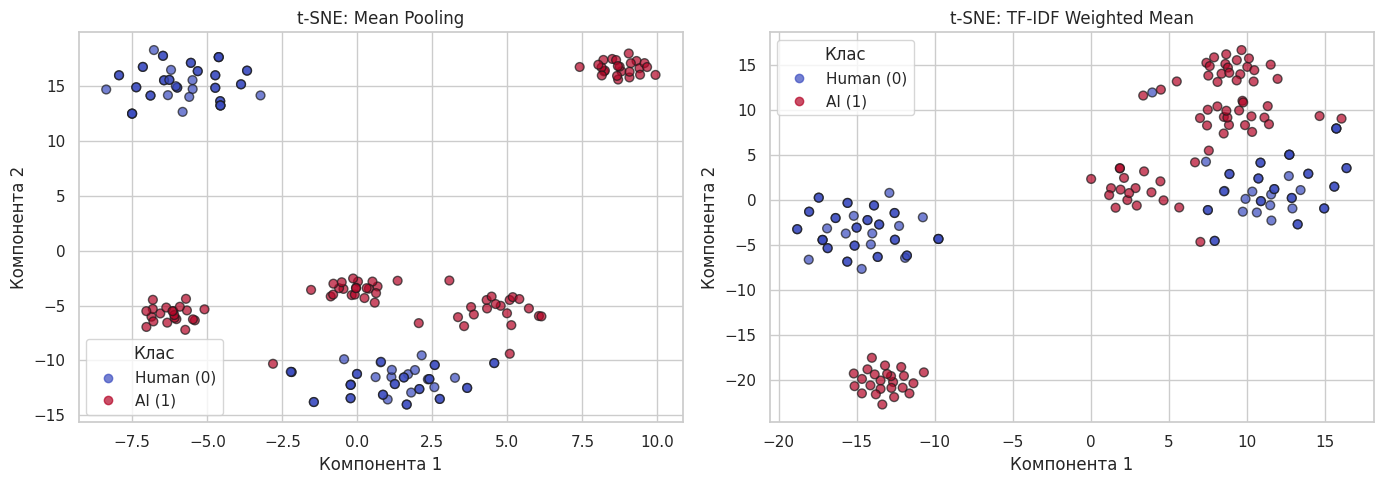

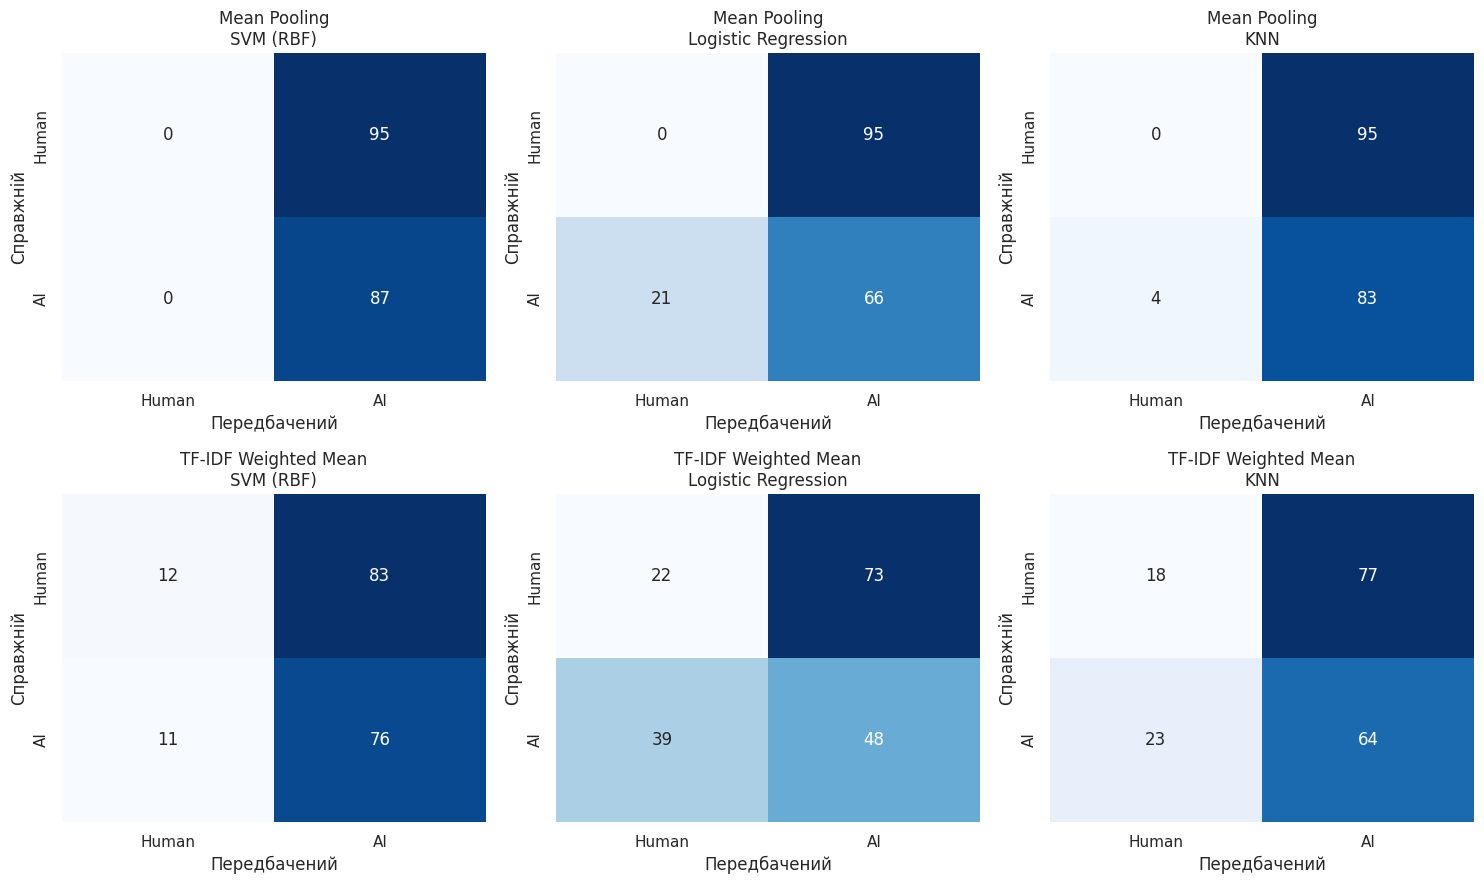

In [ ]:
from sklearn.manifold import TSNE

# 1. t-SNE проекція
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)

for ax, (repr_name, (X_tr, X_te)) in zip(axes, representations.items()):
  X_scaled = StandardScaler().fit_transform(X_te)
  X_embedded = tsne.fit_transform(X_scaled)
  scatter = ax.scatter(
      X_embedded[:, 0],
      X_embedded[:, 1],
      c=y_test,
      cmap='coolwarm',
      alpha=0.7,
      edgecolors='k',
      s=40,
  )
  ax.set_title(f't-SNE: {repr_name}')
  ax.set_xlabel('Компонента 1')
  ax.set_ylabel('Компонента 2')
  handles, _ = scatter.legend_elements()
  ax.legend(handles, ['Human (0)', 'AI (1)'], title='Клас')

plt.tight_layout()
plt.show()

# 2. Матриці плутанини
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
order_repr = ['Mean Pooling', 'TF-IDF Weighted Mean']
order_models = ['SVM (RBF)', 'Logistic Regression', 'KNN']

for row_i, repr_name in enumerate(order_repr):
  for col_i, model_name in enumerate(order_models):
    ax = axes[row_i, col_i]
    pred = predictions[(repr_name, model_name)]
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['Human', 'AI'],
        yticklabels=['Human', 'AI'],
    )
    ax.set_title(f'{repr_name}\n{model_name}')
    ax.set_xlabel('Передбачений')
    ax.set_ylabel('Справжній')

plt.tight_layout()
plt.show()